# 12 完整临床变量与MRI可行性核查

用户已批准本步核查。本步逐字段核查36个临床字段、扫描前时间可知性、双ID映射、公开MRI入口和ROI标签泄漏风险；不拟合扩展临床或影像模型。原始数据保持不变。

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
from IPython.display import display,Image
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from rn_public.ucsd_feature_audit import run,FUTURE_FIELDS
summary=run(ROOT)
audit=pd.read_csv(ROOT/'reports/ucsd_feature_audit/clinical_field_audit.csv')
display(audit[['field','role','observed_timepoints','missing_or_unknown','observed_tumor_timepoints','observed_change_timepoints']])
assert len(audit)==36 and summary['models_fitted_this_step'] is False

,field,role,observed_timepoints,missing_or_unknown,observed_tumor_timepoints,observed_change_timepoints
0,ID,identifier_only,243,0,192,51
1,BraTS ID,identifier_only,243,0,192,51
2,Magnetic Field Strength,acquisition_audit_only,243,0,192,51
3,Manufacturer,acquisition_audit_only,243,0,192,51
4,Manufacturer's Model Name,acquisition_audit_only,243,0,192,51
5,Patient's Age,candidate,243,0,192,51
6,Sex at birth,candidate,243,0,192,51
7,Race,not_primary_candidate,207,36,161,46
8,Ethnicity,not_primary_candidate,146,97,113,33
9,Primary Diagnosis,cohort_definition_audit,243,0,192,51


## 双ID分组检查改变了此前验证的解释

临床ID0038_03对应BraTS-GLI-02289-102；0036的两个时间点也使用同一BraTS患者前缀02289，而0038另两次扫描使用02291。共2个源患者、5个扫描存在交叉映射，不能自行断定究竟是哪份ID错。上轮BraTS患者02289出现在第4和5折，因此零重叠只对临床ID成立，上轮指标现列为待重新验证。

生成的177个双ID连通分组仅是防泄漏的保守分组，不是纠正后的真实患者数。可考虑下一步主分析先隔离5条记录，再重跑分组验证；本步未重训。

In [2]:
ident=pd.read_csv(ROOT/'reports/ucsd_feature_audit/identity_mapping.csv')
display(ident[ident.id_mapping_ambiguous.eq(1)])
overlap=pd.read_csv(ROOT/'reports/ucsd_feature_audit/prior_validation_identity_overlap.csv')
display(overlap)
assert ident.groupby('patient_id').validation_group_conservative.nunique().eq(1).all()
assert ident.groupby('brats_patient_id').validation_group_conservative.nunique().eq(1).all()
assert summary['ambiguous_mapping_timepoints']==5
assert summary['prior_validation_shared_brats_patients']==1

,ID,patient_id,BraTS ID,brats_patient_id,validation_group_conservative,id_mapping_ambiguous,validation_fold
52,UCSD-PTGBM-0036_01,UCSD-PTGBM-0036,BraTS-GLI-02289-100,BraTS-GLI-02289,dualid:UCSD-PTGBM-0036,1,5
53,UCSD-PTGBM-0036_02,UCSD-PTGBM-0036,BraTS-GLI-02289-101,BraTS-GLI-02289,dualid:UCSD-PTGBM-0036,1,5
57,UCSD-PTGBM-0038_01,UCSD-PTGBM-0038,BraTS-GLI-02291-100,BraTS-GLI-02291,dualid:UCSD-PTGBM-0036,1,4
58,UCSD-PTGBM-0038_02,UCSD-PTGBM-0038,BraTS-GLI-02291-101,BraTS-GLI-02291,dualid:UCSD-PTGBM-0036,1,4
59,UCSD-PTGBM-0038_03,UCSD-PTGBM-0038,BraTS-GLI-02289-102,BraTS-GLI-02289,dualid:UCSD-PTGBM-0036,1,4


,ID,patient_id,BraTS ID,brats_patient_id,validation_fold
0,UCSD-PTGBM-0036_01,UCSD-PTGBM-0036,BraTS-GLI-02289-100,BraTS-GLI-02289,5
1,UCSD-PTGBM-0036_02,UCSD-PTGBM-0036,BraTS-GLI-02289-101,BraTS-GLI-02289,5
2,UCSD-PTGBM-0038_03,UCSD-PTGBM-0038,BraTS-GLI-02289-102,BraTS-GLI-02289,4


## 时间方向、缺失与分子字段

偏移为事件日期减扫描日期，正值表示扫描之后。发现7条未来治疗偏移及7条同日先后不明记录，不翻转符号或当作扫描前暴露。首次/最后放疗有2条顺序冲突。初始时间字段混合手术、治疗、诊断，不能改名为“距手术天数”。MGMT/IDH有患者内记录冲突，保留原值，不跨扫描填补。

In [3]:
c=pd.read_csv(ROOT/'data/processed/ucsd_clinical_feature_candidates.csv')
issues=pd.read_csv(ROOT/'reports/ucsd_feature_audit/case_issues.csv')
display(pd.read_csv(ROOT/'reports/ucsd_feature_audit/temporal_field_audit.csv'))
display(issues[['ID','field','raw_value','kind']])
assert set(FUTURE_FIELDS).isdisjoint(c.columns)
for col in [col for col in c if col.startswith(('candidate_days','conditional_days'))]:
    assert c[col].dropna().gt(0).all()
print('Complete-case examples:',json.dumps(summary['complete_case_examples'],indent=2))

,field,numeric_timepoints,before_scan,same_day,after_scan,minimum,maximum
0,Days from Acquisition to Date of initial surge...,198,197,1,0,-2657.0,0.0
1,Days from Acquisition to Date of last surgery ...,55,54,0,1,-2393.0,35.0
2,Days from Acquisition to Date of last follow-up,238,6,0,232,-103.0,3978.0
3,Days from Acquisition to Date of death,200,0,0,200,31.0,2529.0
4,Days from Acquistion to Date of first radiation,121,120,0,1,-2359.0,3697.0
5,Days from Acquistion to Date of last radiation...,121,119,1,1,-2301.0,8.0
6,Days from Acquisition to Date of 1st chemo start,122,122,0,0,-1874.0,-23.0
7,Days from Acquisition to Date of last Avastin ...,22,13,5,4,-136.0,316.0
8,Days from Acquisition to Other treatment dates,0,0,0,0,NaN,NaN


Complete-case examples: {
  "age_sex": {
    "timepoints": 243,
    "patients": 178,
    "tumor": 192,
    "treatment_change": 51
  },
  "age_sex_other_prior": {
    "timepoints": 243,
    "patients": 178,
    "tumor": 192,
    "treatment_change": 51
  },
  "plus_initial_event": {
    "timepoints": 197,
    "patients": 144,
    "tumor": 150,
    "treatment_change": 47
  },
  "plus_MGMT_IDH_raw": {
    "timepoints": 135,
    "patients": 100,
    "tumor": 106,
    "treatment_change": 29
  },
  "strict_last_radiation": {
    "timepoints": 117,
    "patients": 91,
    "tumor": 88,
    "treatment_change": 29
  }
}


,ID,field,raw_value,kind
0,UCSD-PTGBM-0036_01,BraTS ID,BraTS-GLI-02289-100,cross_namespace_identity_conflict
1,UCSD-PTGBM-0036_02,BraTS ID,BraTS-GLI-02289-101,cross_namespace_identity_conflict
2,UCSD-PTGBM-0038_01,BraTS ID,BraTS-GLI-02291-100,cross_namespace_identity_conflict
3,UCSD-PTGBM-0038_02,BraTS ID,BraTS-GLI-02291-101,cross_namespace_identity_conflict
4,UCSD-PTGBM-0038_03,BraTS ID,BraTS-GLI-02289-102,cross_namespace_identity_conflict
5,UCSD-PTGBM-0075_01,Days from Acquisition to Date of initial surge...,0,same_day_order_unknown
6,UCSD-PTGBM-0126_01,Days from Acquisition to Date of last surgery ...,35,future_treatment_offset
7,UCSD-PTGBM-0123_03,Days from Acquistion to Date of first radiation,3697,future_treatment_offset
8,UCSD-PTGBM-0145_01,Days from Acquistion to Date of last radiation...,8,future_treatment_offset
9,UCSD-PTGBM-0008_02,Days from Acquistion to Date of last radiation...,0,same_day_order_unknown


## MRI获取验证层级

读取本轮实际网络请求收据，不在Notebook中反复请求服务器。需要复核时显式运行`python scripts/audit_ucsd_mri_access.py --refresh`与`python scripts/audit_ucsd_mri_inventory.py --refresh`。公开链接取得授权及下载参数，且测试包59个病例目录与临床ID匹配，不等于已取得NIfTI。主包目录请求超时、未配置HTTP网关；本步下载和像素质控数均为0。

In [4]:
access=json.loads((ROOT/'reports/ucsd_feature_audit/mri_access_receipt.json').read_text())
print({k:access[k] for k in ['authorization_method','http_gateway_url','local_ascp_available','source_files_downloaded','pixel_quality_review_complete']})
for p in access['packages']:
    print('Package',p['package_id'])
    print([(q['probe'],q.get('http_status'),q['success'],q.get('error')) for q in p.get('probes',[])])
inventory=json.loads((ROOT/'reports/ucsd_feature_audit/mri_inventory_receipt.json').read_text())
print('Inventory:',inventory)
display(pd.read_csv(ROOT/'reports/ucsd_feature_audit/mri_sample_request.csv')[['ID','BraTS ID','negative_list_dx','download_status']])
assert inventory['folders']==59 and inventory['folder_clinical_ID_match']
assert access['case_level_MRI_join_verified'] is False
assert access['ROI_empirically_verified'] is False

{'authorization_method': 'official_public_link_web_flow; no user account credentials', 'http_gateway_url': None, 'local_ascp_available': False, 'source_files_downloaded': 0, 'pixel_quality_review_complete': False}
Package 1019
[('package_details', 200, True, None), ('file_listing', None, False, 'TimeoutError'), ('connect_download_parameters', 201, True, None), ('http_gateway_download_parameters', 201, True, None)]
Package 1221
[('package_details', 200, True, None), ('file_listing', 200, True, None), ('connect_download_parameters', 201, True, None), ('http_gateway_download_parameters', 201, True, None)]
Inventory: {'package_id': '1221', 'date': '2026-10-29', 'checked_at_utc': '2026-10-29T03:54:23.395669+00:00', 'endpoint': 'https://faspex.cancerimagingarchive.net/aspera/faspex/api/v5/packages/1221/files/received?limit=1000', 'folders_http_status': 200, 'folders': 59, 'patients': 42, 'tumor_timepoints': 49, 'treatment_change_timepoints': 10, 'folder_clinical_ID_match': True, 'folder_name

,ID,BraTS ID,negative_list_dx,download_status
0,UCSD-PTGBM-0014_01,BraTS-GLI-02263-100,NS,not_downloaded
1,UCSD-PTGBM-0001_01,BraTS-GLI-02250-100,PsP (clinically confirmed),not_downloaded
2,UCSD-PTGBM-0015_01,BraTS-GLI-02264-100,PsP (bx proven),not_downloaded
3,UCSD-PTGBM-0119_01,BraTS-GLI-02374-100,Radiation necrosis,not_downloaded
4,UCSD-PTGBM-0003_01,BraTS-GLI-02252-100,NaN,not_downloaded
5,UCSD-PTGBM-0178_02,BraTS-GLI-02433-101,NaN,not_downloaded


## ROI方案与下一步

TCT/ECT/NECT细胞性肿瘤参考标注使用了临床、病理及后续MRI信息，不能直接作为本任务的ROI或预测输入。普通形态学分割也须核查标签盲法和两组适用性。拟用当前扫描FLAIR/T1增强异常区域的统一流程，检查手术腔、空ROI及预训练模型队列重叠；样本未取得前不声称ROI可行。

本步已核查可用字段并记录访问限制。下一步建议先批准隔离ID冲突、冻结少量临床变量并重跑临床基线/扩展模型；MRI在取得列出的少量样本后再进行像素质控。两条路径的最终融合比较必须使用同一批病例和分组。

临床变量可用情况（由本步审计结果生成）：

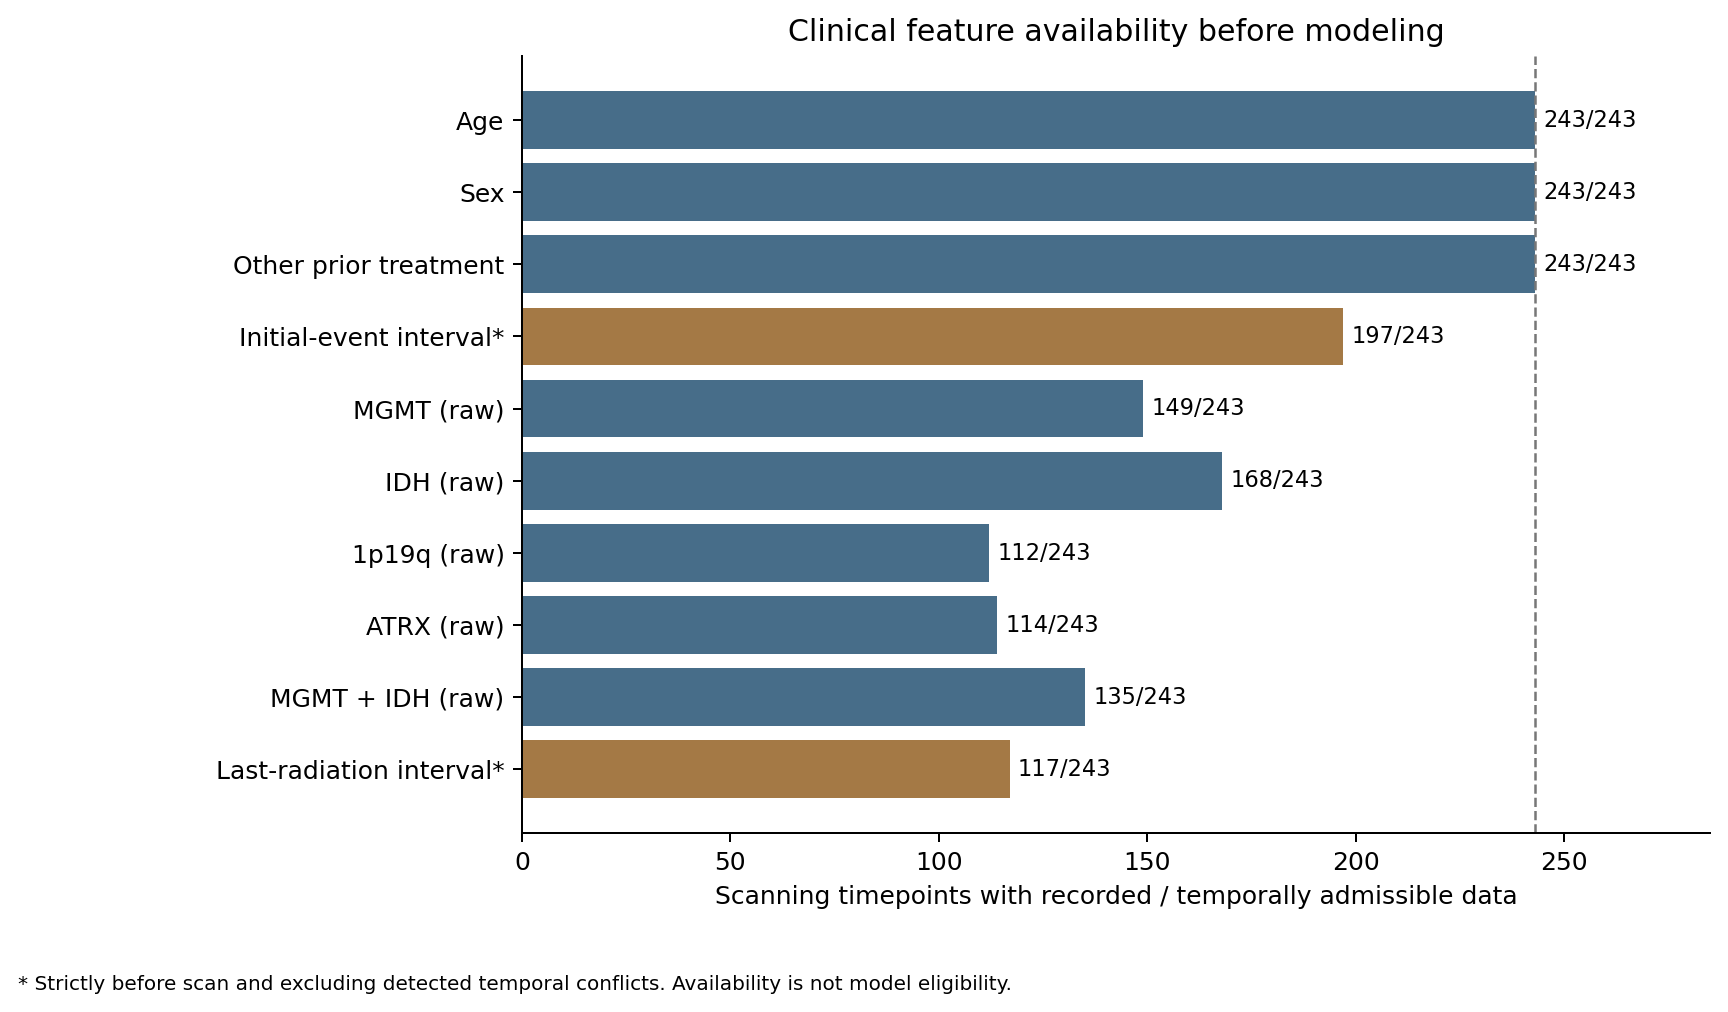

In [5]:
roi=json.loads((ROOT/'reports/ucsd_feature_audit/roi_feasibility.json').read_text())
print(roi['cellular_mask_policy'])
assert roi['roi_empirically_accepted'] is False
assert summary['next_step_requires_user_approval'] is True
assert summary['prior_baseline_metrics_status'].startswith('provisional')
plot=ROOT/'outputs/ucsd-feature-audit-20261029/clinical_feature_availability.png'
if plot.exists():display(Image(filename=str(plot)))
print('Feasibility audit complete. No model fit or MRI pixel QC claimed. Await next-step approval.')

Exclude ground-truth TCT/ECT/NECT masks, their volume, emptiness and file existence from predictors and ROI construction. Descriptor states their creation used clinical/pathological history and prior/subsequent MRI.
Feasibility audit complete. No model fit or MRI pixel QC claimed. Await next-step approval.
